# СИЛАНТ · 02. Тренды и сезонность

**Вопросы:** (1) какой тренд у рынка, типов и сегментов; (2) есть ли сезонность и какая; (3) насколько сезонности можно доверять при ~3 годах данных.

**Подход.** Все модели на логарифмах (коэффициенты = % изменения). Базовая спецификация для всех рядов одинаковая, чтобы результаты были сопоставимы:

`log(y) = уровень + тренд·t + ступенька·1(t ≥ II кв. 2025) + сезонные дамми (2–4 кв.)`

Ступенька во II кв. 2025 — слом, найденный в EDA (этап 01). Её дата выбрана по данным, поэтому значимость слома проверяем отдельно тестом с неизвестной датой (sup-F с бутстрепом). Сезонность проверяем четырьмя независимыми способами и практическим бэктестом.

Моделируются 11 рядов: 4 крупных сегмента ДВС, 4 электро, итоги по типам и рынок. Сегменты ≥5,5 т (нули, десятки штук) — только описательно.

---
**Место в пайплайне:** шаг 2 из 6. Предыдущий: 01 — данные. Следующий: 03 — внешние факторы. Запуск всех шагов: `python update.py`.

**Вход:** `data/processed/market_long.csv`.

**Выход:** `data/processed/trend_summary.csv`, `seasonal_factors.csv`; графики `reports/figures/10–16_*.png`.

**Содержание:** 0. Настройка · 1. Тренд · 2. Сезонность · 3. Выводы · Источники

## 0. Настройка
Импорт библиотек, пути (относительно корня проекта), параметры и фиксированный seed для случайных чисел. Общие функции вынесены в модули `src/`, чтобы ноутбук содержал только логику анализа.

In [1]:
import sys
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
import statsmodels.api as sm

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from silant_data import load_market
from silant_ts import (
    build_series,
    design,
    compare_specs,
    break_scan,
    sup_f_break,
    fit_ts,
    seasonal_factors,
    season_tests,
    mde_by_years,
    perm_test_shares,
    classical_decomp,
    shrink_seasonality,
    rolling_cv,
    BREAK,
)

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
RAW = ROOT / "data/raw/silant_forklift_market.xlsx"
OUT = ROOT / "data/processed"
FIG = ROOT / "reports/figures"
COL = {"ДВС": "#eb6834", "Электро": "#2a78d6", "Рынок": "#52514e"}
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 150,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.6,
        "axes.edgecolor": "#8a8984",
        "font.size": 10,
        "axes.titleweight": "bold",
        "axes.titlesize": 11,
        "lines.linewidth": 2,
    }
)
thous = mt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", " "))
pctf = mt.PercentFormatter(1.0, decimals=0)


def qlab(p):
    return f"{('I', 'II', 'III', 'IV')[p.quarter - 1]} кв. {p.year}"


def qaxis(ax, idx, step=1):
    xs = idx.to_timestamp()
    ax.set_xticks(xs[::step], [qlab(p) for p in idx][::step], rotation=45)


SOURCE_NOTE = "Источник: данные заказчика (СИЛАНТ); расчёты автора."
UNITS = {"12_sa_trend": "Продажи, шт.", "16_backtest": "Ошибка прогноза"}


def save(fig, name):
    # подпись оси Y (единицы) там, где её нет, и источник данных под рисунком
    unit = UNITS.get(name)
    if unit:
        for ax in fig.axes:
            if not ax.get_ylabel() and ax.get_label() != "<colorbar>":
                ax.set_ylabel(unit)
    fig.canvas.draw()
    bottom = fig.get_tightbbox(fig.canvas.get_renderer()).y0 / fig.get_figheight()
    fig.text(0.01, bottom - 0.02, SOURCE_NOTE, fontsize=8, color="#555555", ha="left", va="top")
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()


def color_of(name):
    return (
        COL["ДВС"]
        if name.startswith("ДВС")
        else COL["Электро"]
        if name.startswith("Электро")
        else COL["Рынок"]
    )


long, _, _ = load_market(RAW)
S = build_series(long)
MODEL = [c for c in S if "5,5" not in c]
BIG = ["Рынок", "ДВС", "Электро"]
print("Ряды:", S.columns.tolist())
print("Период:", S.index.min(), "–", S.index.max(), f"({len(S)} кв.)")

Ряды: ['ДВС 1–1,8 т', 'ДВС 2–2,5 т', 'ДВС 3–3,5 т', 'ДВС 3,8–5 т', 'ДВС 5,5 т+', 'Электро 1–1,8 т', 'Электро 2–2,5 т', 'Электро 3–3,5 т', 'Электро 3,8–5 т', 'Электро 5,5 т+', 'ДВС', 'Электро', 'Рынок']
Период: 2023Q1 – 2026Q1 (13 кв.)


## 1. Тренд

### 1.1 Есть ли слом, и когда
Для каждой возможной даты перебираем модель со ступенькой и смотрим сумму квадратов остатков (чем ниже, тем лучше дата объясняет данные). Значимость — sup-F тест (Andrews) с параметрическим бутстрепом: учитывает, что дату мы подбирали сами.

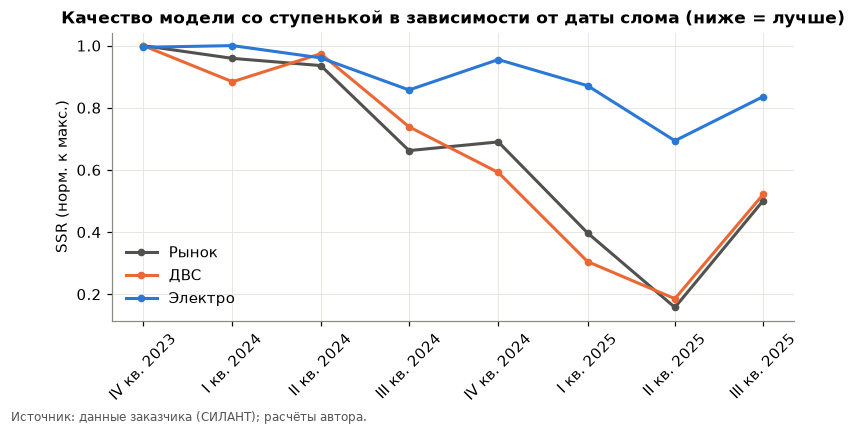

,supF,p_boot,best_date
"ДВС 1–1,8 т",18.386,0.018,II кв. 2025
"ДВС 2–2,5 т",44.050,0.002,II кв. 2025
"ДВС 3–3,5 т",36.034,0.004,II кв. 2025
"ДВС 3,8–5 т",34.591,0.004,I кв. 2025
"Электро 1–1,8 т",15.826,0.029,II кв. 2025
"Электро 2–2,5 т",4.079,0.286,II кв. 2025
"Электро 3–3,5 т",7.992,0.112,I кв. 2024
"Электро 3,8–5 т",7.938,0.114,I кв. 2025
ДВС,52.453,0.002,II кв. 2025
Электро,3.544,0.334,II кв. 2025


In [2]:
scan = pd.DataFrame({c: break_scan(S[c]) for c in BIG})
sup = pd.DataFrame({c: sup_f_break(S[c], n_boot=2000, seed=SEED) for c in MODEL}).T
sup["best_date"] = [qlab(break_scan(S[c]).idxmin()) for c in MODEL]

fig, ax = plt.subplots(figsize=(8, 3.4))
for c in BIG:
    ax.plot(
        scan.index.to_timestamp(), scan[c] / scan[c].max(), color=COL[c], marker="o", ms=4, label=c
    )
qaxis(ax, scan.index)
ax.set_ylabel("SSR (норм. к макс.)")
ax.set_title("Качество модели со ступенькой в зависимости от даты слома (ниже = лучше)")
ax.legend(frameon=False)
save(fig, "10_break_scan")
sup.round(3)

### 1.2 Оценки тренда
- **Факт:** изменение годовых объёмов 2023→2025 и скользящих 4 кварталов (LTM) за последний год.
- **Модель:** квартальный темп тренда и величина ступеньки со II кв. 2025, 90 % доверительные интервалы.
- **AICc:** какая из 8 спецификаций (уровень/тренд × слом/нет × сезон/нет) лучше описывает ряд с учётом числа параметров.

In [3]:
rows, fits = [], {}
LAST = S.index.max()
for c in MODEL:
    y = S[c]
    r, _ = fit_ts(y)
    fits[c] = r
    ci = r.conf_int(0.10)
    cs = compare_specs(y)
    b = cs.loc[cs.AICc.idxmin()]
    spec = (
        ("тренд" if b.trend else "уровень")
        + (" + слом" if b["break"] else "")
        + (" + сезон" if b.season else "")
    )
    ann = y.groupby(y.index.year).sum()
    rows.append(
        {
            "ряд": c,
            "2025/2023": ann[2025] / ann[2023] - 1,
            f"LTM {qlab(LAST)} г/г": y.iloc[-4:].sum() / y.iloc[-8:-4].sum() - 1,
            "тренд, %/кв": np.expm1(r.params.trend),
            "тренд, ДИ 90 %": f"[{np.expm1(ci.loc['trend', 0]):+.1%}; {np.expm1(ci.loc['trend', 1]):+.1%}]",
            "ступенька II кв. 2025": np.expm1(r.params.step),
            "ступенька, ДИ 90 %": f"[{np.expm1(ci.loc['step', 0]):+.0%}; {np.expm1(ci.loc['step', 1]):+.0%}]",
            "слом p (sup-F)": sup.loc[c, "p_boot"],
            "лучшая спецификация (AICc)": spec,
        }
    )
trend = pd.DataFrame(rows).set_index("ряд")
trend.to_csv(OUT / "trend_summary.csv", encoding="utf-8-sig")
fmt = {c: "{:+.0%}" for c in ["2025/2023", f"LTM {qlab(LAST)} г/г", "ступенька II кв. 2025"]}
fmt.update({"тренд, %/кв": "{:+.1%}", "слом p (sup-F)": "{:.3f}"})
trend.style.format(fmt)

,2025/2023,LTM I кв. 2026 г/г,"тренд, %/кв","тренд, ДИ 90 %",ступенька II кв. 2025,"ступенька, ДИ 90 %",слом p (sup-F),лучшая спецификация (AICc)
ряд,,,,,,,,
"ДВС 1–1,8 т",-50%,-54%,-2.1%,[-9.0%; +5.4%],-45%,[-69%; -0%],0.018,уровень + слом
"ДВС 2–2,5 т",-45%,-55%,-0.6%,[-5.4%; +4.4%],-50%,[-67%; -27%],0.002,уровень + слом
"ДВС 3–3,5 т",-62%,-58%,-4.7%,[-10.3%; +1.3%],-47%,[-68%; -14%],0.004,уровень + слом
"ДВС 3,8–5 т",-58%,-53%,-6.7%,[-11.7%; -1.4%],-33%,[-57%; +4%],0.004,тренд
"Электро 1–1,8 т",-21%,-27%,+0.5%,[-3.1%; +4.1%],-30%,[-47%; -7%],0.029,уровень + слом
"Электро 2–2,5 т",-18%,-26%,+3.5%,[-1.6%; +8.8%],-38%,[-59%; -8%],0.286,уровень
"Электро 3–3,5 т",+42%,+6%,+6.7%,[+0.0%; +13.8%],-22%,[-53%; +31%],0.112,уровень
"Электро 3,8–5 т",+69%,+52%,+6.2%,[-0.1%; +13.1%],+9%,[-34%; +79%],0.114,тренд
ДВС,-55%,-55%,-3.4%,[-7.5%; +0.9%],-45%,[-61%; -22%],0.002,уровень + слом


Те же оценки на графике: тренд за квартал и величина ступеньки во II кв. 2025 с 90 %-ными доверительными интервалами по каждому ряду.

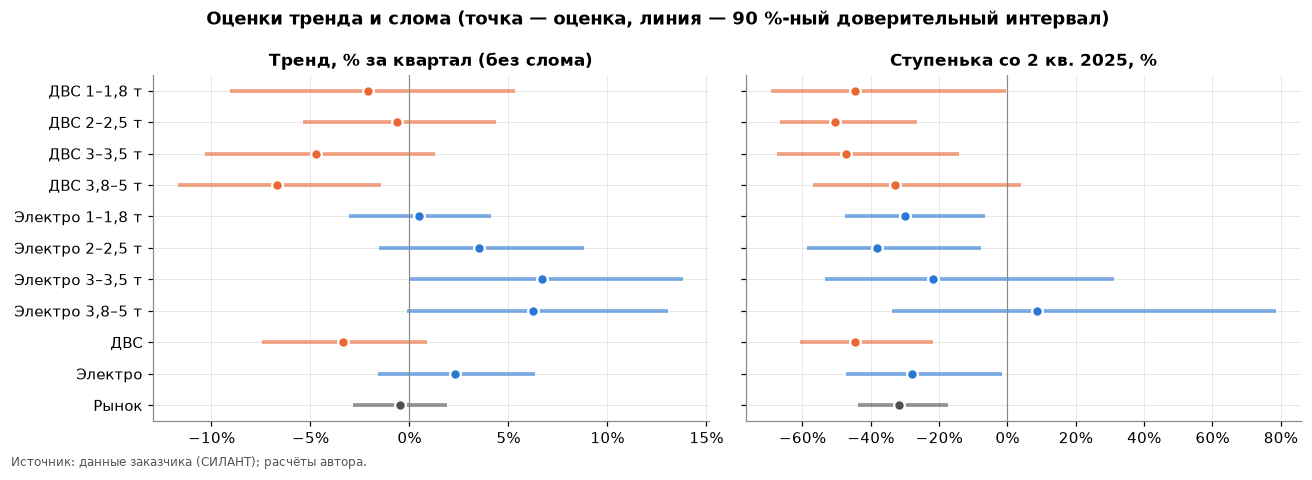

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
order = MODEL[::-1]
for ax, par, title in [
    (axes[0], "trend", "Тренд, % за квартал (без слома)"),
    (axes[1], "step", "Ступенька со 2 кв. 2025, %"),
]:
    for i, c in enumerate(order):
        r = fits[c]
        lo, hi = np.expm1(r.conf_int(0.10).loc[par])
        est = np.expm1(r.params[par])
        ax.hlines(i, lo, hi, color=color_of(c), lw=2.5, alpha=0.6)
        ax.plot(est, i, "o", color=color_of(c), ms=7, mec="white", mew=1.5)
    ax.axvline(0, color="#8a8984", lw=0.8)
    ax.set_title(title)
    ax.xaxis.set_major_formatter(pctf)
axes[0].set_yticks(range(len(order)), order)
fig.suptitle(
    "Оценки тренда и слома (точка — оценка, линия — 90 %-ный доверительный интервал)",
    fontweight="bold",
)
fig.tight_layout()
save(fig, "11_trend_forest")

### 1.3 Рынок, типы: факт, сезонно скорректированный ряд и тренд со сломом

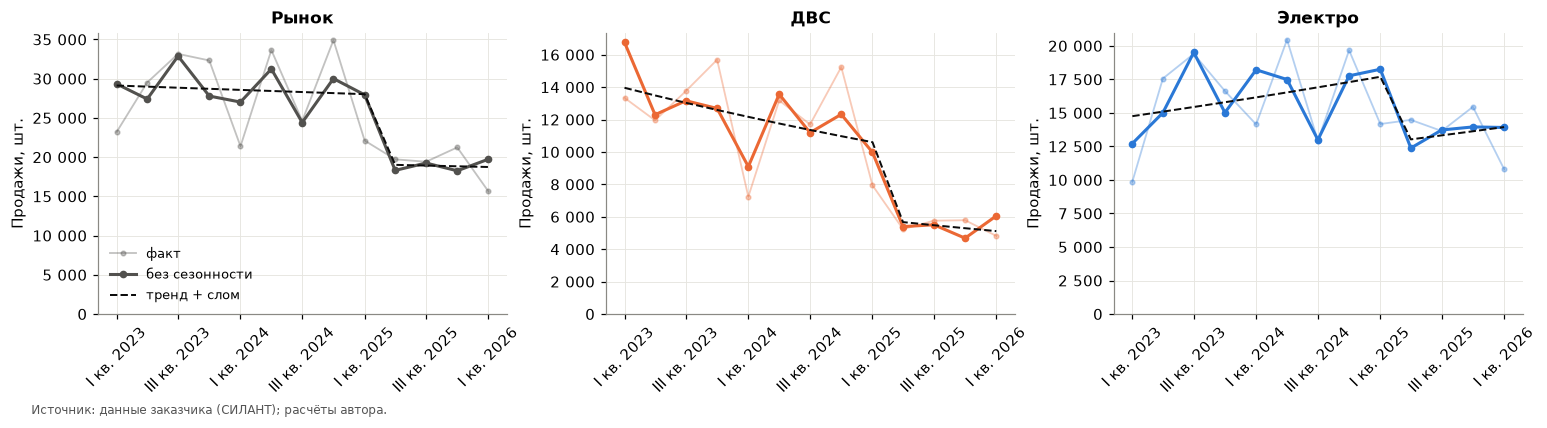

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, c in zip(axes, BIG):
    y = S[c]
    r = fits[c]
    sf = seasonal_factors(r).factor.to_numpy()
    sa = y / sf[y.index.quarter - 1]
    X = design(y.index, True, BREAK, False)
    tr = np.exp(X @ r.params[X.columns]) * np.exp(
        np.log(sf).mean() + r.params[["Q2", "Q3", "Q4"]].sum() / 4
    )
    x = y.index.to_timestamp()
    ax.plot(x, y, color=COL[c], alpha=0.35, marker="o", ms=3, lw=1.2, label="факт")
    ax.plot(x, sa, color=COL[c], marker="o", ms=4, label="без сезонности")
    ax.plot(x, tr, color="#0b0b0b", ls="--", lw=1.3, label="тренд + слом")
    ax.set_title(c)
    ax.yaxis.set_major_formatter(thous)
    ax.set_ylim(bottom=0)
    qaxis(ax, y.index, 2)
axes[0].legend(frameon=False, fontsize=8.5)
fig.tight_layout()
save(fig, "12_sa_trend")

## 2. Сезонность

### 2.1 Сезонные коэффициенты (базовая модель)
Коэффициент 0,80 = квартал на 20 % ниже среднего квартала при прочих равных. Интервалы — 90 % ДИ.

,1 кв,2 кв,3 кв,4 кв,F_p,q1_effect,q1_p,mde_q1,sigma
"ДВС 1–1,8 т",0.73,1.00,1.10,1.25,0.177,-0.347,0.049,0.394,0.296
"ДВС 2–2,5 т",0.89,0.90,1.04,1.20,0.281,-0.145,0.234,0.285,0.198
"ДВС 3–3,5 т",0.81,0.98,1.05,1.19,0.290,-0.244,0.102,0.340,0.245
"ДВС 3,8–5 т",0.72,1.09,1.02,1.26,0.053,-0.360,0.013,0.312,0.221
"Электро 1–1,8 т",0.81,1.16,1.00,1.07,0.066,-0.244,0.015,0.217,0.144
"Электро 2–2,5 т",0.78,1.18,1.00,1.08,0.127,-0.280,0.031,0.290,0.202
"Электро 3–3,5 т",0.67,1.30,0.93,1.24,0.040,-0.417,0.011,0.356,0.260
"Электро 3,8–5 т",0.78,0.81,1.25,1.27,0.073,-0.284,0.063,0.345,0.250
ДВС,0.80,0.97,1.05,1.24,0.065,-0.263,0.023,0.255,0.173
Электро,0.78,1.17,0.99,1.11,0.042,-0.287,0.009,0.233,0.157


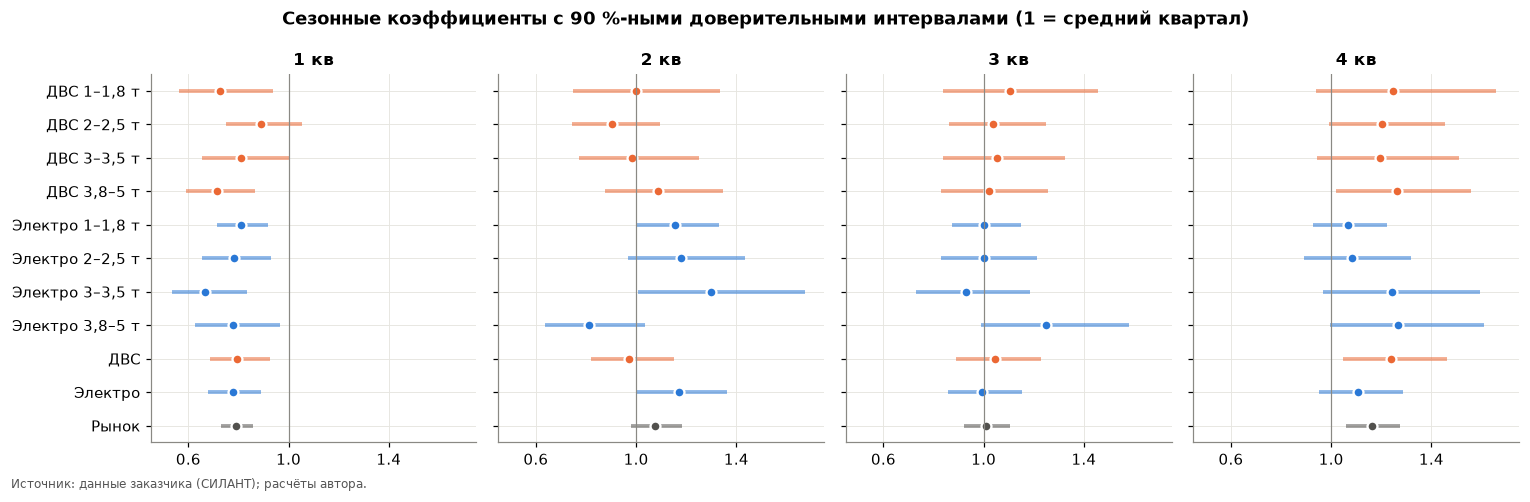

In [6]:
SF = {c: seasonal_factors(fits[c]) for c in MODEL}
ST = pd.DataFrame({c: season_tests(fits[c]) for c in MODEL}).T
sf_tab = pd.DataFrame({c: SF[c].factor for c in MODEL}).T.round(2)
display(sf_tab.join(ST[["F_p", "q1_effect", "q1_p", "mde_q1", "sigma"]].astype(float).round(3)))

fig, axes = plt.subplots(1, 4, figsize=(14, 4.4), sharey=True, sharex=True)
order = MODEL[::-1]
for k, ax in enumerate(axes):
    for i, c in enumerate(order):
        f = SF[c].iloc[k]
        ax.hlines(i, f.lo, f.hi, color=color_of(c), lw=2.5, alpha=0.55)
        ax.plot(f.factor, i, "o", color=color_of(c), ms=6.5, mec="white", mew=1.5)
    ax.axvline(1, color="#8a8984", lw=0.8)
    ax.set_title(SF[MODEL[0]].index[k])
    ax.set_xlim(0.45, 1.75)
    ax.set_xticks([0.6, 1, 1.4])
axes[0].set_yticks(range(len(order)), order)
fig.suptitle(
    "Сезонные коэффициенты с 90 %-ными доверительными интервалами (1 = средний квартал)",
    fontweight="bold",
)
fig.tight_layout()
save(fig, "13_seasonal_forest")

### 2.2 Устойчивость к выбору модели: эффект I квартала при разных способах учёта тренда
Если сезонность реальна, её оценка не должна сильно зависеть от того, как мы убрали тренд.
- **доли в году** — средняя доля 1 кв. в годовом объёме 2023–2025 (без модели);
- **эффекты года** — `log y = год + сезон` на 2023–2025 (уровень свой в каждом году, слом внутри 2025 не учтён);
- **тренд** — `log y = тренд + сезон`;
- **тренд + слом** — базовая модель.

,доли в году,эффекты года,тренд,тренд + слом
"ДВС 1–1,8 т",-20%,-22%,-31%,-35%
"ДВС 2–2,5 т",+11%,+7%,-9%,-14%
"ДВС 3–3,5 т",-2%,-4%,-20%,-24%
"ДВС 3,8–5 т",-18%,-18%,-34%,-36%
"Электро 1–1,8 т",-14%,-15%,-22%,-24%
"Электро 2–2,5 т",-22%,-25%,-25%,-28%
"Электро 3–3,5 т",-41%,-42%,-40%,-42%
"Электро 3,8–5 т",-36%,-38%,-29%,-28%
ДВС,-6%,-9%,-23%,-26%
Электро,-23%,-24%,-27%,-29%


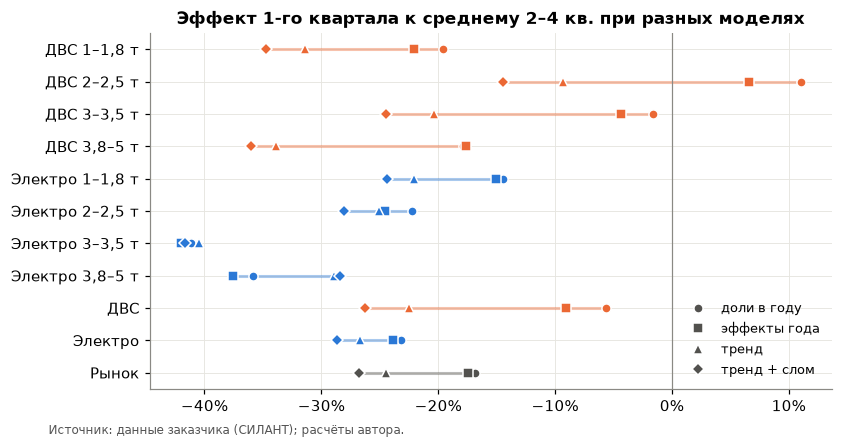

In [7]:
full = S[S.index.year <= 2025]


def q1_effect(y, how):
    if how == "доли в году":
        sh = y.groupby(y.index.year).transform(lambda s: s / s.sum())
        m = sh.groupby(y.index.quarter).mean()
        return m[1] / m[[2, 3, 4]].mean() - 1
    if how == "эффекты года":
        X = pd.get_dummies(y.index.year).astype(float).set_index(y.index)
        X = X.join(design(y.index, False, None, True)[["Q2", "Q3", "Q4"]])
    else:
        X = design(y.index, True, BREAK if how == "тренд + слом" else None, True)
    r = sm.OLS(np.log(y), X).fit()
    return np.expm1(-r.params[["Q2", "Q3", "Q4"]].mean())


hows = ["доли в году", "эффекты года", "тренд", "тренд + слом"]
sens = pd.DataFrame(
    {h: {c: q1_effect(full[c] if h in hows[:2] else S[c], h) for c in MODEL} for h in hows}
)
display(sens.style.format("{:+.0%}"))

fig, ax = plt.subplots(figsize=(8, 4.2))
mk = dict(zip(hows, ["o", "s", "^", "D"]))
for i, c in enumerate(MODEL[::-1]):
    v = sens.loc[c]
    ax.hlines(i, v.min(), v.max(), color=color_of(c), lw=2, alpha=0.4)
    for h in hows:
        ax.plot(
            v[h], i, mk[h], color=color_of(c), ms=6, mec="white", mew=1, label=h if i == 0 else None
        )
ax.axvline(0, color="#8a8984", lw=0.8)
ax.set_yticks(range(len(MODEL)), MODEL[::-1])
ax.xaxis.set_major_formatter(pctf)
leg = ax.legend(frameon=False, fontsize=8.5, loc="lower right")
for h in leg.legend_handles:
    h.set_color("#52514e")
ax.set_title("Эффект 1-го квартала к среднему 2–4 кв. при разных моделях")
save(fig, "14_q1_sensitivity")

### 2.3 Точный перестановочный тест
Внутри каждого года случайно переставляем метки кварталов (все 24³ = 13 824 комбинации для 2023–2025) и смотрим, как часто «случайная» сезонность получается не слабее наблюдаемой. Тест без допущений о распределении, но с малой мощностью; доли внутри года смещены трендом.

In [8]:
perm = []
for c in MODEL:
    m3, p3 = perm_test_shares(S[c], [2023, 2024, 2025])
    m2, p2 = perm_test_shares(S[c], [2023, 2024])
    perm.append(
        {
            "ряд": c,
            **{f"{k} кв": v for k, v in zip(range(1, 5), m3.round(3))},
            "p (2023–25)": p3,
            "p (2023–24, до слома)": p2,
        }
    )
perm = pd.DataFrame(perm).set_index("ряд")
perm.round(3)

,1 кв,2 кв,3 кв,4 кв,p (2023–25),"p (2023–24, до слома)"
ряд,,,,,,
"ДВС 1–1,8 т",0.211,0.242,0.258,0.289,0.688,0.708
"ДВС 2–2,5 т",0.270,0.212,0.240,0.278,0.620,0.458
"ДВС 3–3,5 т",0.247,0.237,0.242,0.274,0.925,0.208
"ДВС 3,8–5 т",0.215,0.275,0.237,0.273,0.542,0.208
"Электро 1–1,8 т",0.222,0.277,0.245,0.257,0.620,0.500
"Электро 2–2,5 т",0.206,0.276,0.246,0.272,0.497,0.458
"Электро 3–3,5 т",0.164,0.291,0.228,0.317,0.071,0.417
"Электро 3,8–5 т",0.176,0.187,0.309,0.329,0.052,0.292
ДВС,0.239,0.236,0.244,0.281,0.752,0.375


### 2.4 Сколько данных нужно, чтобы уверенно увидеть сезонность
Минимально обнаружимый эффект (MDE): какой провал I квартала модель отличит от шума с мощностью 80 % при α = 0,10. Зависит от шума ряда σ (остатки базовой модели) и числа лет.

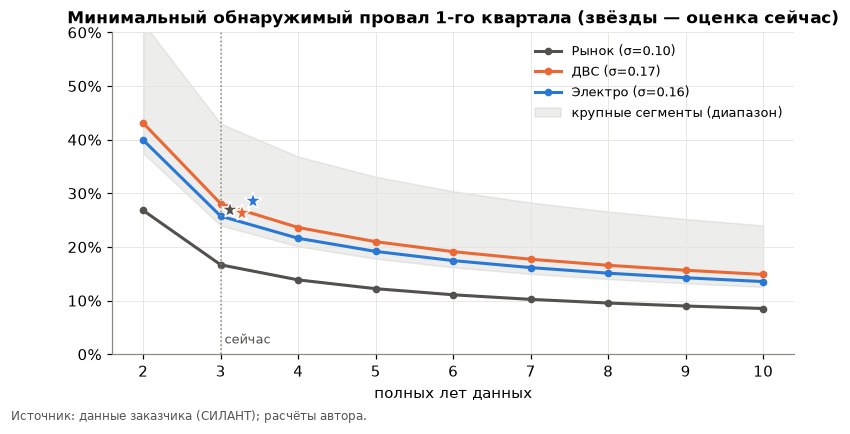

,3,5,8,10
"ДВС 1–1,8 т",43%,33%,27%,24%
"ДВС 2–2,5 т",31%,24%,19%,17%
"ДВС 3–3,5 т",37%,28%,23%,20%
"ДВС 3,8–5 т",34%,26%,21%,19%
"Электро 1–1,8 т",24%,18%,14%,13%
"Электро 2–2,5 т",32%,24%,19%,17%
"Электро 3–3,5 т",39%,30%,24%,21%
"Электро 3,8–5 т",38%,29%,23%,21%
ДВС,28%,21%,17%,15%
Электро,26%,19%,15%,14%


In [9]:
years = np.arange(2, 11)
fig, ax = plt.subplots(figsize=(8, 3.8))
for c in BIG:
    m = mde_by_years(ST.loc[c, "sigma"], years)
    ax.plot(years, m, color=COL[c], marker="o", ms=4, label=f"{c} (σ={ST.loc[c, 'sigma']:.2f})")
seg_sig = ST.loc[[c for c in MODEL if c not in BIG], "sigma"]
lo, hi = mde_by_years(seg_sig.min(), years), mde_by_years(seg_sig.max(), years)
ax.fill_between(years, lo, hi, color="#8a8984", alpha=0.15, label="крупные сегменты (диапазон)")
for dx, c in zip([0.12, 0.27, 0.42], BIG):
    ax.plot(3 + dx, -ST.loc[c, "q1_effect"], "*", color=COL[c], ms=12, mec="white")
ax.axvline(3, color="#8a8984", ls=":", lw=1)
ax.text(3.05, 0.02, "сейчас", fontsize=8.5, color="#52514e")
ax.yaxis.set_major_formatter(pctf)
ax.set_xlabel("полных лет данных")
ax.set_ylim(0, 0.6)
ax.set_title("Минимальный обнаружимый провал 1-го квартала (звёзды — оценка сейчас)")
ax.legend(frameon=False, fontsize=8.5)
save(fig, "15_mde_years")
pd.DataFrame({c: mde_by_years(ST.loc[c, "sigma"]) for c in MODEL}).T.style.format("{:.0%}")

### 2.5 Общая сезонность с частичным объединением (shrinkage)
Сезонные эффекты сегментов шумные, но похожи. Эмпирический Байес: каждый сегмент стягивается к общему профилю своего типа тем сильнее, чем менее точна его собственная оценка. Если разброс между сегментами не больше шума (τ ≈ 0), все получают общий профиль.

In [10]:
rec = []
for t in ["ДВС", "Электро"]:
    segs = [c for c in MODEL if c.startswith(t + " ")]
    est = pd.DataFrame({c: np.log(SF[c].factor) for c in segs}).T
    se = pd.DataFrame({c: SF[c].se_log for c in segs}).T
    shr, pooled, tau = shrink_seasonality(est, se)
    print(
        f"{t}: общий профиль",
        np.exp(pooled).round(2).to_dict(),
        "| τ между сегментами",
        tau.round(3).to_dict(),
    )
    for c in segs:
        rec.append(
            {
                "ряд": c,
                **{f"{q} собств.": np.exp(est.loc[c, q]) for q in est.columns},
                **{f"{q} итог": np.exp(shr.loc[c, q]) for q in est.columns},
            }
        )
rec = pd.DataFrame(rec).set_index("ряд")
sf_final = rec[[c for c in rec if c.endswith("итог")]]
sf_final.columns = [c.replace(" итог", "") for c in sf_final.columns]
sf_final = sf_final.div(np.exp(np.log(sf_final).mean(axis=1)), axis=0)  # геом. среднее = 1
for c in BIG:
    sf_final.loc[c] = SF[c].factor.to_numpy()
sf_final.to_csv(OUT / "seasonal_factors.csv", encoding="utf-8-sig")
rec.round(2)

ДВС: общий профиль {'1 кв': 0.79, '2 кв': 0.98, '3 кв': 1.05, '4 кв': 1.22} | τ между сегментами {'1 кв': 0.023, '2 кв': 0.0, '3 кв': 0.0, '4 кв': 0.0}
Электро: общий профиль {'1 кв': 0.78, '2 кв': 1.1, '3 кв': 1.03, '4 кв': 1.12} | τ между сегментами {'1 кв': 0.0, '2 кв': 0.135, '3 кв': 0.032, '4 кв': 0.0}


,1 кв собств.,2 кв собств.,3 кв собств.,4 кв собств.,1 кв итог,2 кв итог,3 кв итог,4 кв итог
ряд,,,,,,,,
"ДВС 1–1,8 т",0.73,1.00,1.10,1.25,0.79,0.98,1.05,1.22
"ДВС 2–2,5 т",0.89,0.90,1.04,1.20,0.80,0.98,1.05,1.22
"ДВС 3–3,5 т",0.81,0.98,1.05,1.19,0.79,0.98,1.05,1.22
"ДВС 3,8–5 т",0.72,1.09,1.02,1.26,0.79,0.98,1.05,1.22
"Электро 1–1,8 т",0.81,1.16,1.00,1.07,0.78,1.14,1.02,1.12
"Электро 2–2,5 т",0.78,1.18,1.00,1.08,0.78,1.15,1.02,1.12
"Электро 3–3,5 т",0.67,1.30,0.93,1.24,0.78,1.20,1.02,1.12
"Электро 3,8–5 т",0.78,0.81,1.25,1.27,0.78,0.94,1.04,1.12


### 2.6 Практическая проверка: помогает ли сезонность прогнозу
Проверка на истории (бэктест) со скользящим началом: обучаем на данных до квартала T (T = IV кв. 2024 … IV кв. 2025) и прогнозируем на 1–4 квартала вперёд. Метрика: средняя |log(факт/прогноз)| (≈ средняя ошибка в %). Методы: наивный (последний квартал), сезонный наивный (тот же квартал год назад), среднее 4 кварталов без сезона, среднее 4 кварталов × сезонный профиль (собственный или общий рыночный).

⚠️ В окно бэктеста попадает слом II кв. 2025, поэтому оценка сильно зависит от него. Всего 5 точек начала прогноза — это иллюстрация, а не надёжное сравнение методов.

группа,ДВС (ряды со сломом),Рынок,Электро,все ряды
method,,,,
наивный (последний квартал),47.5%,26.3%,27.2%,36.3%
сезонный наивный (год назад),71.2%,37.1%,26.4%,47.8%
среднее 4 кв. (без сезона),64.7%,34.1%,25.6%,44.1%
среднее 4 кв. × свой сезон,62.9%,33.1%,23.7%,42.4%
среднее 4 кв. × сезон рынка,63.9%,33.1%,22.4%,42.2%


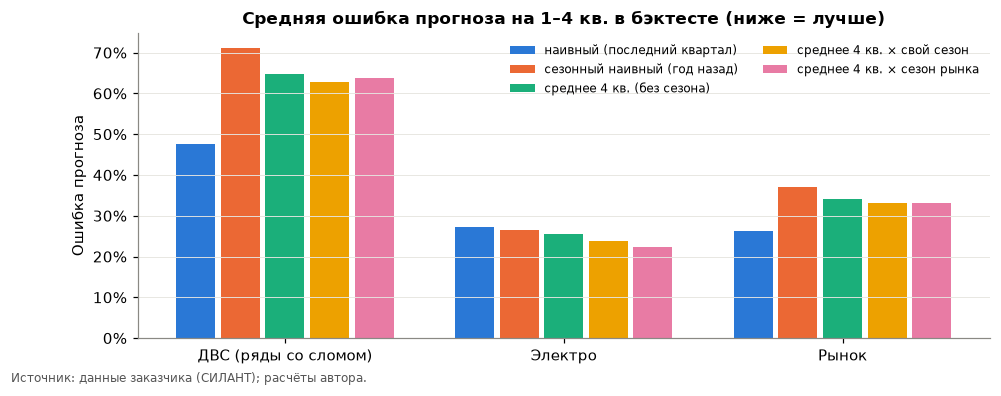

In [11]:
cv = pd.concat([rolling_cv(S[c], season_ref=S["Рынок"]).assign(ряд=c) for c in MODEL])
cv["группа"] = np.where(
    cv["ряд"].str.startswith("ДВС"),
    "ДВС (ряды со сломом)",
    np.where(cv["ряд"].str.startswith("Электро"), "Электро", "Рынок"),
)
res_cv = cv.groupby(["группа", "method"]).abs_log_err.mean().unstack(0)
res_cv["все ряды"] = cv.groupby("method").abs_log_err.mean()
display(res_cv.style.format("{:.1%}").highlight_min(axis=0, props="font-weight:bold"))

m_order = res_cv.index.tolist()
mcol = dict(zip(m_order, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
fig, ax = plt.subplots(figsize=(10, 3.6))
groups = ["ДВС (ряды со сломом)", "Электро", "Рынок"]
w = 0.16
for j, m in enumerate(m_order):
    ax.bar(
        np.arange(3) + (j - 2) * w, res_cv.loc[m, groups], width=w - 0.02, color=mcol[m], label=m
    )
ax.set_xticks(range(3), groups)
ax.yaxis.set_major_formatter(pctf)
ax.grid(axis="x", visible=False)
ax.set_title("Средняя ошибка прогноза на 1–4 кв. в бэктесте (ниже = лучше)")
ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper right")
save(fig, "16_backtest")

### Проверка актуальности выводов
Текст выводов ниже написан по данным до I кв. 2026 г. Если в файле появился новый квартал, эта ячейка выведет предупреждение; таблицы и графики выше при этом пересчитываются автоматически.

In [12]:
from IPython.display import Markdown, display
from silant_data import load_market as _lm
_last = str(_lm(ROOT / 'data/raw/silant_forklift_market.xlsx')[0].quarter.max())
if _last != "2026Q1":
    display(Markdown(f"> ⚠️ **Текст выводов ниже написан по данным до 2026Q1**, а в файле данные уже до **{_last}**. "
                     "Все таблицы и графики выше пересчитаны автоматически; конкретные цифры в тексте могли устареть — "
                     "актуальные значения см. в таблицах выше, в `reports/summary.html` и `reports/silant_forecast.xlsx`."))
else:
    print("Текст выводов соответствует текущим данным (до 2026Q1).")

Текст выводов соответствует текущим данным (до 2026Q1).


## 3. Выводы

### 3.1 Тренд
- **Рынок не снижается плавно: в II кв. 2025 он «ступенькой» перешёл на новый уровень и дальше стоит.** Ступенька −32 % (90 % ДИ −44…−17 %), тест на слом с неизвестной датой p < 0,001, лучшая дата — II кв. 2025. Собственный тренд рынка без слома ≈ 0 (−0,5 %/кв, ДИ −2,8…+1,9 %). Без сезонности: ~27–30 тыс. шт./кв. до I кв. 2025 → ~18–20 тыс. после. Лучшая по AICc модель рынка — «уровень + слом + сезон».
- **ДВС — главный источник слома:** −45 % (ДИ −61…−22 %), p ≈ 0,002; во всех крупных сегментах ДВС −33…−50 %. Поверх слома возможен продолжающийся спад −3 %/кв, но ДИ включает ноль (−7,5…+0,9 %). Сезонно скорректированный уровень ДВС после слома — ~5–6 тыс. шт./кв. (было ~12–13 тыс.).
- **Электро в целом тоже просел в 2025** (без сезонности в среднем ~16 тыс. → ~13,5–14 тыс. шт./кв., LTM −19 % г/г), но форму спада — ступенька или плавное снижение — по данным не различить (sup-F p = 0,33). Лёгкие электро (1–2,5 т) снижаются вместе с рынком.
- **Из сегментов с заметным объёмом растут только электро 3–3,5 т и 3,8–5 т:** тренд +6–7 % за квартал, нижняя граница ДИ ≈ 0, то есть рост вероятен, но его темп не определён. Важный сигнал: у 3–3,5 т рост замедлился (2025/2023 +42 %, но LTM г/г всего +6 %); у 3,8–5 т продолжается (LTM +52 %, база маленькая: ~2,5 тыс. шт./год).

### 3.2 Сезонность — что видно
- **Устойчивый факт один: I квартал ниже среднего на ~20–30 %.** Эффект отрицательный во всех 11 рядах. У электро и рынка он почти не зависит от способа учёта тренда (электро −23…−29 %, рынок −17…−27 %). Общий профиль: электро 0,78 / 1,10 / 1,03 / 1,12, ДВС 0,79 / 0,98 / 1,05 / 1,22 (1–4 кв.).
- **У ДВС оценка I квартала целиком зависит от модели** (от −6 % до −26 %): слом внутри 2025 года смешивается с сезонностью (I кв. 2025 пришёлся ещё на «старый» уровень). Без правильно учтённого слома сезонность ДВС не оценить.
- **Пик IV квартала у ДВС (+20–25 %) ненадёжен:** он был в 2023 и 2024, в 2025 его не было. Разница между 2, 3 и 4 кварталами (5–15 %) меньше порога обнаружения — статистически это шум.
- **Сегменты внутри типа по сезонности не отличаются от общего профиля** (разброс между сегментами τ ≈ 0 почти по всем кварталам), поэтому для прогноза берём общий профиль типа (частичное объединение) → `data/processed/seasonal_factors.csv`.

### 3.3 Насколько можно доверять сезонности при ~3 годах
**Ответ: только в самом общем виде — «I квартал слабый», на уровне рынка и типов. Точный квартальный профиль и сезонность отдельных сегментов по этим данным не определены.** Почему:
1. **Каждый квартал наблюдался 3 раза** (1-й — 4 раза). Сезонный коэффициент — это среднее по трём числам, одно из которых в 2025 году искажено сломом.
2. **Шум сопоставим с сезонностью.** Нерегулярные колебания (σ остатков) — 10 % у рынка, 15–17 % у типов, 14–30 % у сегментов, тогда как размах сезонности ±20 %. Минимальный провал I квартала, который можно надёжно увидеть за 3 года, — ~17 % у рынка, 25–28 % у типов, 22–43 % у сегментов. Наблюдаемый эффект (~27 %) выше порога у рынка, на пороге у электро и ниже у ДВС и большинства сегментов. У рынка при 5 годах порог опустится до ~12 %; у сегментов даже 10 лет дают порог 13–24 % — посегментная сезонность на таких данных принципиально плохо оценивается.
3. **Выводы зависят от метода.** Параметрические тесты при правильном учёте тренда и слома находят провал I квартала (рынок p = 0,001, электро p = 0,009). Непараметрический перестановочный тест значимой сезонности не находит ни в одном ряду (p ≥ 0,05). Кроме того, проверяется 11 рядов, и они не независимы: сегменты складываются в итоги, так что «эффект есть во всех рядах» — меньше подтверждений, чем кажется.
4. **Практически сезонность — эффект второго порядка.** В бэктесте за 2025 год учёт сезонности снижал ошибку прогноза электро с ~26 % до ~22 %. У ДВС и рынка всё решает слом: наивный прогноз «как в последнем квартале» оказался лучше всех сезонных методов. Сезонный наивный прогноз (тот же квартал год назад) — худший почти везде, потому что переносит в прогноз старый уровень.
5. **Внешняя логика совпадает:** слабый I квартал типичен для B2B-техники (январские праздники, утверждение бюджетов и лизинговых лимитов). Это повышает доверие к общему выводу, но не к точным коэффициентам.

### 3.4 Что это значит для прогноза и плана
- В моделях сезонность — общий профиль по типу с интервалами (неопределённость коэффициентов включаем в симуляцию прогноза), а не отдельные коэффициенты по сегментам.
- Главный источник неопределённости — уровень рынка и возможные новые сломы, а не сезонность. Сценарии должны описывать уровень (продолжение нового плато, восстановление, дальнейшее падение), а сезонность просто накладывается сверху.
- Для производственного плана надёжнее опираться на полугодовые и годовые объёмы; поквартальную разбивку давать как ориентир: «I квартал на 20–30 % ниже среднего», без точных процентов по 2–4 кварталам.
- Слом II кв. 2025 учитываем явно: тренд 2023–2024 в прогноз не переносим.
- Каждый новый год данных заметно сужает интервалы (при 5 годах порог обнаружения у рынка ~12 %) — оценки сезонности пересчитываются автоматически при обновлении файла.

## Источники
1. Данные: `data/processed/market_long.csv` (из файла заказчика, см. ноутбук 01).
2. Andrews D.W.K. Tests for parameter instability and structural change with unknown change point // Econometrica. 1993. Vol. 61, № 4. P. 821–856 — идея sup-F теста на слом.
3. DerSimonian R., Laird N. Meta-analysis in clinical trials // Controlled Clinical Trials. 1986. Vol. 7, № 3. P. 177–188 — оценка разброса между сегментами, на которой построено частичное объединение сезонных коэффициентов.
4. Hyndman R.J., Athanasopoulos G. Forecasting: Principles and Practice. 3rd ed. Melbourne: OTexts, 2021. https://otexts.com/fpp3/ — тренд, сезонность, проверка прогноза на скользящем начале.